# UKFによる状態推定


1. UKFによる状態推定
2. UKFによる外乱推定
3. UKFによるパラメータ推定
4. UKFによる外乱・パラメータの同時推定

## 運動方程式

以下の剛性が非線形なバネ-マス-ダンパ系の運動方程式とする。

$$
m \ddot{x} +  c \dot{x} + k x |x| =  u + d
$$

- $m$ : 慣性 [$kg$]
- $c$ : 粘性 [$Ns/m$]
- $k$ : 剛性 [$N/m^2$]
- $u$ : 既知の制御入力 [$N$]
- $d$ : 未知外乱 [$N$]

## 状態方程式

状態ベクトル$X$とする。

$$
X = \begin{bmatrix} x \\ v \end{bmatrix}
$$

これより、連続時間の状態方程式は以下となる。

$$
\begin{bmatrix}
\dot{x} \\ \dot{v}
\end{bmatrix} =
\begin{bmatrix}
v \\
\frac{1}{m}\left( u - c v - k x|x| + d \right)
\end{bmatrix}
$$

前進Euler法による離散時間モデルは、以下となる。
$$
\begin{array}{c}
X_{n+1} = f(X_n ,u_n) + w_n \\ \downarrow \\
\begin{bmatrix}
x_{n+1} \\ v_{n+1}
\end{bmatrix} =
\begin{bmatrix}
x_{n} + \Delta t v_n \\
v_n + \frac{\Delta t}{m}\left( u_n - c v_n - k x_n|x_n| + d_n \right)
\end{bmatrix} + w_n
\end{array}
$$

$w_n$ は $\mathcal{N}(0, Q_n)$ に従うプロセスノイズである。


## 観測方程式

状態推定を行うため、観測値は速度とする。

$$
\begin{array}{c}
z_{n+1} = h(x_{n+1}) + r_{n+1} \\ \downarrow \\
z_{n+1} = v_{n+1} + r_{n+1}
\end{array}
$$

$r_{n+1}$は $\mathcal{N}(0, R_{n+1})$ に従う観測ノイズである。


## 1. 状態推定

状態推定では未知外乱は$d=0$として行う。

状態数は$n=2$である。

シグマポイントに関するパラメータは$\alpha=1, \kappa = 0, \beta = 2$とする。

$$
\lambda = \alpha^2(n+\kappa) -n
$$

平均計算用重み

$$
W_0^{(m)} = \frac{\lambda}{n+\lambda} , \quad W_i^{(m)} = \frac{1}{2(n+\lambda)}, \space i=1,...,4
$$

共分散計算用重み

$$
W_0^{(c)} = W_0^{(m)} + (1 - \alpha^2 + \beta) , \quad W_i^{(c)} = W_i^{(m)}, \space i=1,...,4
$$

以上を用いて、1ループの処理は以下となる。

### 1.1 UKF１ループの処理

#### 1.1.1 シグマポイントの計算

時刻$k$時の事後推定の推定状態を$\hat{x}_{k|k} \in \mathcal{R}^{2 \times 1}$、誤差共分散行列を$P_{k|k} \in \mathcal{R}^{2 \times 2}$とし、シグマポイント $\chi_{k|k} \in \mathcal{R}^{2 \times 1}$ を計算する。

$$
\begin{aligned}
\chi_{k|k}^{(0)} &= \hat{x}_{k|k} \\
\chi_{k|k}^{(i)} &= \hat{x}_{k|k} + \sqrt{n+\lambda} \left(\sqrt{P_{{k|k}}}\right)_i, \space i = 1,2 \\
\chi_{k|k}^{(n+i)} &= \hat{x}_{k|k} - \sqrt{n+\lambda} \left(\sqrt{P_{{k|k}}}\right)_i, \space i = 1,2 \\
\end{aligned}
$$

#### 1.1.2 次状態の予測値(事前推定値)を計算

シグマポイント$\chi_{k|k}$を状態方程式を通過させ、次状態のシグマポイント$\chi_{k+1|k}$を求める。

$$
\chi_{k+1|k}^{(i)} = f(\chi_{k|k}^{(i)}, u_k), \space i=0,..,4
$$

$\chi_{k+1|k}$の平均値を計算し、次状態の予測値を求める。

$$
\hat{x}_{k+1|k} = \sum_{i=0}^{4}W_i^{(m)}\chi_{k+1|k}^{(i)}
$$

次状態の予測誤差共分散を求める。

$$
P_{k+1|k} = \sum_{i=0}^{4} W_i^{(c)} \left( \chi_{k+1|k}^{(i)} - \hat{x}_{k+1|k} \right) \left( \chi_{k+1|k}^{(i)} - \hat{x}_{k+1|k} \right)^T + Q_k
$$

#### 1.1.3 事前推定値からシグマポイントを計算

事前推定値の$\hat{x}_{k+1|k}$と$P_{k+1|k}$からシグマポイント$\psi_{k+1|k}  \in \mathcal{R}^{2 \times 1}$を求める。

$$
\begin{aligned}
\psi_{k+1|k}^{(0)} &= \hat{x}_{k+1|k} \\
\psi_{k+1|k}^{(i)} &= \hat{x}_{k+1|k} + \sqrt{n+\lambda} \left(\sqrt{P_{{k+1|k}}}\right)_i, \space i = 1,2 \\
\psi_{k+1|k}^{(n+i)} &= \hat{x}_{k+1|k} - \sqrt{n+\lambda} \left(\sqrt{P_{{k+1|k}}}\right)_i, \space i = 1,2 \\
\end{aligned}
$$

#### 1.1.4 観測値の予測値を計算

シグマポイント$\psi_{k+1|k}$を観測方程式を通過させ、観測空間でのシグマポイント$Z_{k+1} \in \mathcal{R}^{1 \times 1}$を求める。

$$
Z_{k+1}^{(i)} = h(\psi_{k+1|k}^{(i)}) , \space i=0,...,4
$$

$Z_{k+1}$の平均値を計算し、観測値の予測値$\hat{z}_{k+1|k}  \in \mathcal{R}^{1 \times 1}$を求める。

$$
\hat{z}_{k+1|k} = \sum_0^{4} W_i^{(m)} Z_{k+1}^{(i)}
$$

観測値の予測誤差共分散$S_{k+1} \in \mathcal{R}^{1 \times 1}$を求める。

$$
S_{k+1} = \sum_{i=0}^{4} W_i^{(c)} \left( Z_{k+1}^{(i)} - \hat{z}_{k+1|k} \right) \left( Z_{k+1}^{(i)} - \hat{z}_{k+1|k} \right)^T + R_{k+1}
$$

#### 1.1.5 交差共分散を計算

シグマポイント$\psi_{k+1|k}, Z_{k+1}$から交差共分散$P_{xz} \in \mathcal{R}^{2 \times 1}$ を計算する。

$$
P_{xz} = \sum_{i=0}^4 W_i^{(c)} \left( \psi_{k+1|k}^{(i)} - \hat{x}_{k+1|k} \right) \left( Z_{k+1}^{(i)} - \hat{z}_{k+1|k} \right)^T
$$

#### 1.1.6 Kalma Gainを計算

観測値の予測誤差共分散$S_{k+1}$ と交差共分散 $P_{xz}$からKalman Gain $K_{k+1} \in \mathcal{R}^{2 \times 1}$ を計算する。

$$
K_{k+1} = P_{xz}S_{k+1}^{-1}
$$

#### 1.1.7 状態の更新

システムの測定値$z_{k+1} \in \mathcal{R}^{1 \times 1}$ と観測値の予測値 $\hat{z}_{k+1|k}$ からinnovation $\tilde{z}_{k+1} \in \mathcal{R}^{1 \times 1}$ を求める。

$$
\tilde{z}_{k+1} = z_{k+1} - \hat{z}_{k+1|k}
$$

時刻$k+1$時の事後推定の状態$\hat{x}_{k+1|k+1} \in \mathcal{R}^{2 \times 1}$ を事前推定の状態$\hat{x}_{k+1|k}$とKalman Gain $K_{k+1}$により以下で更新する。

$$
\hat{x}_{k+1|k+1} = \hat{x}_{k+1|k} + K_{k+1} \tilde{z}_{k+1}
$$

#### 1.1.8 誤差共分散の更新

時刻$k+1$時の事後推定の誤差共分散の$P_{k+1|k+1} \in \mathcal{R}^{2 \times 2}$ を事前状態の誤差共分散$P_{k+1|k}$、Kalman Gain$K_{k+1}$と観測値の予測誤差共分散$S_{k+1}$を持ちて以下で更新する。

$$
P_{k+1|k+1} = P_{k+1|k} - K_{k+1} S_{k+1} K_{k+1}^T
$$

これで時刻$k+1$での事後推定値が求まる。以降は1.1に戻り、各時刻での推定を行う。

### 1.2 Python Code


In [44]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Optional

In [45]:
@dataclass
class Parameters:

    dt:float  = 1e-3 # Simulation Step

    m:float = 10 # 慣性 [kg]
    c:float = 0.1 # 粘性 [N s/m]
    k:float = 1.4 # 剛性 [N/m^2]

    # 状態数
    nx : int = 2

    # 観測数
    nz : int = 1

    # 誤差共分散行列の初期値
    P_init : np.ndarray = field(
        default_factory=lambda: np.diag([1e2, 1e2]), compare=False
    )

    # プロセスノイズの分散Q
    Q: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )

    # 観測ノイズの分散R
    R: np.ndarray = field(
        default_factory=lambda: np.array([[1e-2]]), compare=False
    )

    alpha:float  = 1.0
    beta:float = 2.0
    kappa:float = 0.0

def fake_real_system(X_n:np.ndarray, u_n:float, d_n:float , params:Parameters):
    x_n, v_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.c * v_n - params.k * x_n * np.abs(x_n) + d_n)
    return np.array([x_next,v_next])

def fake_mesurement_value(X_n:np.ndarray, params:Parameters):
    x_n, v_n = X_n
    return np.array([v_n])

def fake_process_noize(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(params.nx), cov=params.Q)

def fake_mesurement_noiz(params:Parameters):
    return np.random.normal(loc=0, scale=np.sqrt(params.R[0,0]), size=params.nz)

def generate_sigma_points(x_mean:np.ndarray, P:np.ndarray, params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    U = np.linalg.cholesky((n + lam) * P)

    # シグマポイントの計算
    sigmas = np.zeros((2*n + 1, n))
    sigmas[0] = x_mean
    for i in range(n):
        sigmas[i+1] = x_mean + U[:,i]
        sigmas[n+i+1] = x_mean - U[:,i]

    return sigmas

def genrate_weights(params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    # 重み計算
    weights_mean = np.zeros(2*n + 1)
    weights_cov = np.zeros(2*n + 1)

    weights_mean[0] = lam / (n+lam)
    weights_cov[0] = weights_mean[0] + (1 - params.alpha**2 + params.beta)

    for i in range(1, 2*n+1):
        weights_mean[i] = 1.0 / (2*(n + lam))
        weights_cov[i] = weights_mean[i]

    return weights_mean, weights_cov



In [46]:
def calculate_UKF_one_loop(hat_x:np.ndarray, P:np.ndarray, u:float, d:float, z:float, params:Parameters):

    # シグマポイントを計算
    sigmas = generate_sigma_points(hat_x, P, params)
    # 重みの計算
    w_m , w_c = genrate_weights(params)

    # シグマポイントを状態方程式に通過させる
    chis = np.array([fake_real_system(s, u, d, params) for s in sigmas])


    # 事前推定値の状態を計算
    x_pred = np.sum(w_m[:, None] * chis, axis=0)

    # 事前推定値の分散を計算
    P_pred = params.Q.copy()
    for i in range(len(w_m)):
        diff = chis[i] - x_pred
        P_pred += w_c[i] * np.outer(diff, diff)

    # シグマポイントを計算
    psi = generate_sigma_points(x_pred, P_pred, params)

    # シグマポイントを観測方程式に通過させる
    Z = np.array([fake_mesurement_value(s, params) for s in psi])

    # 予測観測値を求める
    z_pred = np.sum(w_m[:, None]* Z, axis=0)

    # 観測値の予測誤差共分散を求める
    S_pred = params.R.copy()
    for i in range(len(w_m)):
        diff = Z[i] - z_pred
        S_pred += w_c[i] * np.outer(diff, diff)

    # 交差共分散を求める
    Pxz = np.zeros((params.nx, params.nz))
    for i in range(len(w_m)):
        diff_x = psi[i] - x_pred
        diff_z = Z[i] - z_pred
        Pxz += w_c[i] * np.outer(diff_x, diff_z)

    # カルマンゲインの計算
    K = np.linalg.solve(S_pred, Pxz.T).T

    # innovation
    tilde_z = z - z_pred

    # 事後推定 状態
    x_est = x_pred + K @ tilde_z

    # 事後推定 共分散行列
    P_est = P_pred - K @ S_pred @ K.T
    P_est = 0.5*(P_est + P_est.T)
    return x_est, P_est

    


In [47]:
def simulation(X_init: np.ndarray,X_est_init:np.ndarray, u_array:np.ndarray, params:Parameters):

    X_history = []
    X_est_history = []
    time_array = []

    X_history.append(X_init)
    X_est_history.append(X_est_init)
    time_array.append(0)
    P_est = params.P_init
    n = len(u_array)

    for i in range(n):
        w_k = fake_process_noize(params)

        # システムの状態
        X_real = fake_real_system(X_history[i], u_array[i], 0, params) + w_k

        # システムの観測値
        z = fake_mesurement_value(X_real, params) + fake_mesurement_noiz(params)

        # UFKによる状態推定
        X_est, P_est = calculate_UKF_one_loop(X_est_history[i], P_est, u_array[i], 0.0, z, params)

        X_est_history.append(X_est)
        X_history.append(X_real)

        time_array.append(params.dt * (i+1))

    return np.asarray(time_array), np.asarray(X_history), np.asarray(X_est_history)
    

In [101]:
dt = 1e-2 # [s]
duration = 10 #[s]
sampling_point = int(duration/dt)
time_window = np.linspace(0, duration, sampling_point)
u_array = time_window* 1

X_init = np.array([0,0])
X_est_init = np.array([0,0])

params = Parameters(
    dt=dt,
    k=1.0,
    c=0.1,
    Q=np.diag([1e-4,1e-4]),
    R=np.array([[1e-4]]),
    P_init=np.diag([1e1, 1e1])
)

t_array, x_array, x_est_array = simulation(X_init, X_est_init, u_array, params)

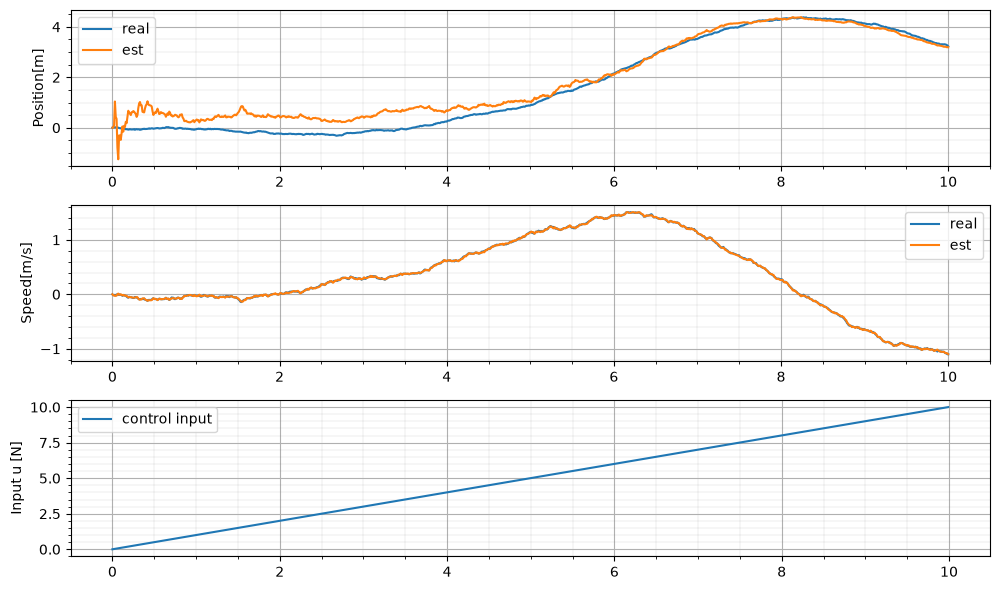

In [102]:
fig, ax = plt.subplots(3,1, figsize=(10,6))

ax[0].set_ylabel("Position[m]")
ax[0].plot(t_array, x_array[:,0], label="real")
ax[0].plot(t_array, x_est_array[:,0], label="est")

ax[1].set_ylabel("Speed[m/s]")
ax[1].plot(t_array, x_array[:,1], label="real")
ax[1].plot(t_array, x_est_array[:,1], label="est")

ax[2].set_ylabel("Input u [N]")
ax[2].plot(t_array[:len(u_array)], u_array, label="control input")

for i in range(3):
    ax[i].grid()
    ax[i].grid(which='minor', lw=0.1, color='grey')
    ax[i].minorticks_on()

    ax[i].legend()

plt.tight_layout()
plt.show()